# Project 1 – Step 1: the sentiment datasets

Covers the "Dataset" topic of the brief: size, instances per label, document lengths, a few examples,
and what the label balance means for the metric (accuracy vs macro-F1).

Datasets (Hugging Face):
- `mteb/imdb` – full-length movie reviews, binary sentiment.
- `stanfordnlp/sst2` – Stanford Sentiment Treebank, binary, short sentences/phrases.

Run with `part1/` as working directory, kernel = micromamba env `nlp1`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

pd.set_option("display.max_colwidth", 200)
SEED = 0

# Harmonise both datasets to the same schema: DataFrame with columns text, label (0=neg, 1=pos), split.
def to_frames(dsdict, text_col):
    return {
        split: pd.DataFrame({"text": ds[text_col], "label": ds["label"]}).assign(split=split)
        for split, ds in dsdict.items()
    }

imdb = to_frames(load_dataset("mteb/imdb"), "text")
sst2 = to_frames(load_dataset("stanfordnlp/sst2"), "sentence")
datasets = {"IMDB": imdb, "SST-2": sst2}
LABEL_NAMES = {0: "negative", 1: "positive", -1: "hidden (-1)"}

## 1. Size and instances per label

In [2]:
rows = []
for name, splits in datasets.items():
    for split, df in splits.items():
        counts = df["label"].value_counts().sort_index()
        row = {"dataset": name, "split": split, "n_docs": len(df)}
        for lab, c in counts.items():
            row[LABEL_NAMES[lab]] = c
        rows.append(row)
label_table = pd.DataFrame(rows).fillna(0)
for c in ["negative", "positive", "hidden (-1)"]:
    if c in label_table: label_table[c] = label_table[c].astype(int)
label_table["pos_share"] = label_table["positive"] / (label_table["negative"] + label_table["positive"])
label_table

,dataset,split,n_docs,negative,positive,hidden (-1),pos_share
0,IMDB,train,24904,12432,12472,0,0.500803
1,IMDB,test,24678,12266,12412,0,0.502958
2,SST-2,train,67349,29780,37569,0,0.557826
3,SST-2,validation,872,428,444,0,0.509174
4,SST-2,test,1821,0,0,1821,NaN


**Reading the table**

- SST-2's `test` split has label `-1` for every row: GLUE hides these labels, so it **cannot be used for scoring**.
  Our held-out test set has to come from labelled data (e.g. the `validation` split, or a split carved out of train).
- IMDB `train`/`test` are both labelled. Counts are 24,904 / 24,678 instead of the original 25,000 / 25,000, because the
  `mteb` version is deduplicated.
- Check `pos_share` below for balance (close to 0.5 = balanced).

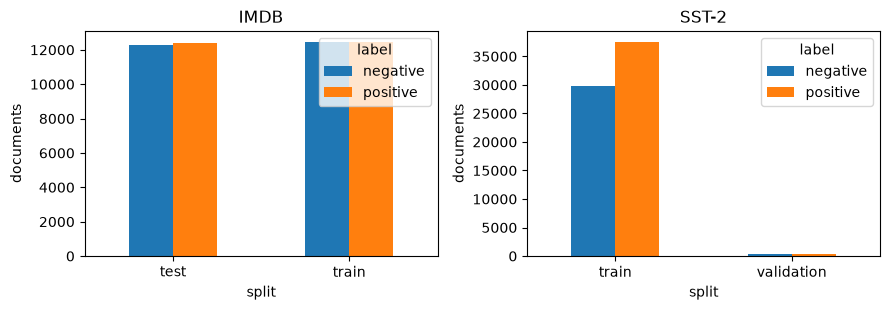

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (name, splits) in zip(axes, datasets.items()):
    labelled = pd.concat([d[d.label >= 0] for d in splits.values()])
    ct = labelled.groupby(["split", "label"]).size().unstack().rename(columns=LABEL_NAMES)
    ct.plot.bar(ax=ax, rot=0)
    ax.set_title(name); ax.set_ylabel("documents")
plt.tight_layout(); plt.show()

## 2. Document lengths

In [4]:
def length_stats(df):
    words = df["text"].str.split().str.len()
    chars = df["text"].str.len()
    return pd.Series({
        "n": len(df), "words_mean": words.mean(), "words_median": words.median(),
        "words_p95": words.quantile(.95), "words_max": words.max(), "words_min": words.min(),
        "chars_mean": chars.mean(),
    })

len_table = pd.DataFrame({
    (name, split): length_stats(df) for name, splits in datasets.items() for split, df in splits.items()
}).T.round(1)
len_table

n  words_mean  words_median  words_p95  words_max  \
IMDB  train       24904.0       234.0         174.0      599.0     2470.0   
      test        24678.0       228.7         172.0      583.0     2278.0   
SST-2 train       67349.0         9.4           7.0       26.0       52.0   
      validation    872.0        19.5          19.0       34.4       47.0   
      test         1821.0        19.2          18.0       35.0       56.0   

                  words_min  chars_mean  
IMDB  train            10.0      1326.4  
      test              4.0      1294.6  
SST-2 train             1.0        53.5  
      validation        2.0       105.8  
      test              2.0       103.0

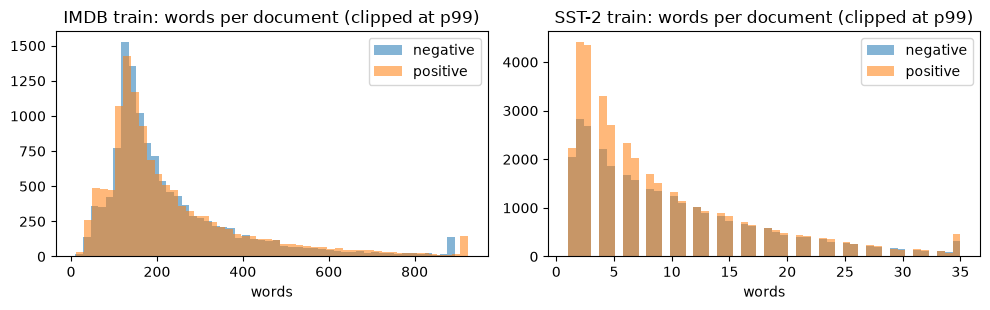

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (name, splits) in zip(axes, datasets.items()):
    train = splits["train"]
    for lab in (0, 1):
        w = train.loc[train.label == lab, "text"].str.split().str.len()
        ax.hist(w.clip(upper=w.quantile(.99)), bins=50, alpha=.55, label=LABEL_NAMES[lab])
    ax.set_title(f"{name} train: words per document (clipped at p99)")
    ax.set_xlabel("words"); ax.legend()
plt.tight_layout(); plt.show()

## 3. Examples

Random sample (fixed seed) per dataset and label. Note SST-2 train contains many short *phrases* (sub-sentence
constituents from the treebank), while its validation split contains whole sentences.

In [6]:
for name, splits in datasets.items():
    print("=" * 20, name, "=" * 20)
    train = splits["train"]
    for lab in (0, 1):
        for t in train[train.label == lab].sample(3, random_state=SEED)["text"]:
            print(f"[{LABEL_NAMES[lab]:8s}] {t[:300]!r}")

==================== IMDB ====================
[negative] "I saw this movie twice. I can't believe Pintilie made such a fantasy movie. I'm also a movie/theatre director and I know what I speak. This is not Romania anymore, but I see the events are happening in the same period with the incident from 11 September. No story, no plot, nothing. No conclusion, no"
[negative] "In spite of the great future-design touches, the clever Asimov premise, and Will Smith's dependable cool performance, this movie doesn't live up to expectations. The clichés come thick and fast; (waking from a recurring nightmare, maverick cop has his badge revoked by hardass lieutenant, to list mor"
[negative] "The funniest scene of this movie is probably when our saviours get their medals and plaques and whatnot. So the basic idea is, the police outnumbers these gangsters by like a million to one, but they're powerless because the villains' guns are just a bit bigger. I guess police ammo just kinda bounce"
[positive] 

## 4. Sanity checks that matter later (duplicates / leakage, SST-2 phrase vs sentence)

In [7]:
for name, splits in datasets.items():
    tr = splits["train"]
    dup_within = tr["text"].duplicated().sum()
    print(f"{name}: duplicate texts inside train = {dup_within}")
    # conflicting labels for identical text
    conflict = tr.groupby("text")["label"].nunique().gt(1).sum()
    print(f"{name}: texts with conflicting labels in train = {conflict}")
    for other, df in splits.items():
        if other == "train": continue
        overlap = df["text"].isin(set(tr["text"])).sum()
        print(f"{name}: {other} texts that also appear in train = {overlap} / {len(df)}")

IMDB: duplicate texts inside train = 0
IMDB: texts with conflicting labels in train = 0


IMDB: test texts that also appear in train = 0 / 24678
SST-2: duplicate texts inside train = 371
SST-2: texts with conflicting labels in train = 5


SST-2: validation texts that also appear in train = 0 / 872


SST-2: test texts that also appear in train = 0 / 1821


In [8]:
# SST-2: how short is the training data compared with validation?
s = sst2
for split in ("train", "validation"):
    w = s[split]["text"].str.split().str.len()
    print(f"SST-2 {split}: median {w.median():.0f} words, share with <=5 words = {(w<=5).mean():.1%}")

SST-2 train: median 7 words, share with <=5 words = 42.5%
SST-2 validation: median 19 words, share with <=5 words = 2.8%


## 5. What the label balance means for the metric

- **IMDB** is essentially perfectly balanced (50.1% / 50.3% positive in train / test). Majority baseline ≈ 50%, so
  **accuracy is a fair headline metric** and macro-F1 will be ~identical.
- **SST-2 train** is mildly skewed: 55.8% positive (37,569 vs 29,780), so the majority baseline is ~56%. Validation is
  balanced (50.9%). Here **macro-F1 is easier to defend**; report the majority baseline alongside.
- SST-2 `test` is unlabelled (-1), so it cannot be used. A held-out test set must be carved from labelled data.
- Whichever metric we pick, use the same metric on every CV fold for every system (the Bayesian test pairs folds).

### Things the TA could ask / to remember
- Lengths differ hugely: IMDB ~234 words/review (median 174, max 2470) vs SST-2 train ~9 words (median 7). SST-2 train is
  mostly *phrases* (42.5% have <=5 words) while validation/test are full sentences (~19 words): a train/eval distribution
  mismatch if we train on phrases and evaluate on sentences.
- SST-2 train has 371 duplicated texts and 5 texts with conflicting labels (phrase-level treebank noise) -> must
  deduplicate / keep duplicates out of different CV folds, otherwise folds leak.
- IMDB text contains HTML (`<br /><br />`); the tokenizer will see it unless we clean it.
- IMDB has no overlap between train and test; mteb's version is deduplicated (24,904 / 24,678 rather than 25k / 25k).
